# Cell annotation

## Imports

In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:95% !important; }</style>"))
import warnings
warnings.filterwarnings("ignore") # umap deprecation warnings related to numba do not concern us.

In [2]:
import functools as fn
import itertools as it

import numpy as np
import pandas as pd

import sklearn
from sklearn.utils import Bunch
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.manifold import TSNE
from sklearn.preprocessing import FunctionTransformer
from umap import umap_ as umap

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import plotnine as pn
from plotnine import *

In [3]:
import scanpy as sc

from scboolseq.utils import parse_data_directory, parse_pickles
from scboolseq import scBoolSeq

In [4]:
# Source - https://stackoverflow.com/a/52858398
# Posted by user4234032, modified by community. See post 'Timeline' for change history
# Retrieved 2026-04-22, License - CC BY-SA 4.0

import os
notebook_path = os.path.abspath("1. Clusterization.ipynb")

In [5]:
#from celltypist import models
from scipy.sparse import csr_matrix

In [6]:
%ls *csv

counts_hvgs.csv                      sc_metadata.csv*
dataset_hvgs.csv*                    scboolseq_inferred_observations.csv*
merged_dataset.csv


In [118]:
import anndata as ad

In [11]:
#import scarches as sca

In [106]:
import scvi

### Helper functions and constants

Here we define dictionary that maps Cell Ontology types into *Herault 2023* defined HSC subtypes.

In [12]:
cell_type_mapping = {
    # --- Komórki Macierzyste i Progenitorowe ---
    'hematopoietic stem cell': 'iHSC',
    'hematopoietic precursor cell': 'preDiff',
    'megakaryocyte-erythroid progenitor cell': 'pMk',
    'granulocyte monocyte progenitor cell': 'preDiff',
    
    # --- Ukierunkowanie Limfoidalne (pLymph) ---
    'lymphoid lineage restricted progenitor cell': 'pLymph',
    'early pro-B cell': 'pLymph',
    'late pro-B cell': 'pLymph',
    'precursor B cell': 'pLymph',
    'immature B cell': 'pLymph',
    'naive B cell': 'pLymph',
    'B cell': 'pLymph',
    'plasma cell': 'pLymph',
    'naive T cell': 'pLymph',
    'CD4-positive, alpha-beta T cell': 'pLymph',
    'CD8-positive, alpha-beta T cell': 'pLymph',
    'mature alpha-beta T cell': 'pLymph',
    'natural killer cell': 'pLymph',
    'innate lymphoid cell': 'pLymph',
    
    # --- Ukierunkowanie Erytroidalne (pEr) ---
    'erythroid progenitor cell, mammalian': 'pEr',
    'proerythroblast': 'pEr',
    'erythroblast': 'pEr',
    
    # --- Ukierunkowanie Mieloidalne (pNeuMast) ---
    'granulocytopoietic cell': 'pNeuMast',
    'granulocyte': 'pNeuMast',
    'neutrophil': 'pNeuMast',
    'eosinophil': 'pNeuMast',
    'basophil': 'pNeuMast',
    'mast cell': 'pNeuMast',
    'promonocyte': 'pNeuMast',
    'monocyte': 'pNeuMast',
    'macrophage': 'pNeuMast',
    'conventional dendritic cell': 'pNeuMast',
    'plasmacytoid dendritic cell': 'pNeuMast',
    
    # --- Komórki Nienależące do linii HSPC (Nie dotyczy) ---
    'stromal cell': None,
    'endothelial cell': None
}

### Overview of the pipeline:

1. Manual annotation methods  
   a) Binarization based
    * Import HVGs
    * Train a `scBoolSeq` instance
    * Inspect the distribution of categories
    * Define a series of markers (known a priori)
    * Binarise (coarse-grain) the HVG pseudocount dataframe
    * Query the binary dataframe for cells matching the defined markers
   
   b) Clusterization based (**from markers to clusters**)  
   c) Clusterization based (**from clusters to markers**)
2. Automatic annotation methods
   a) Based on pre-defined classifier (**CellTypist**)  
   b) Based on self-trained classifier (**Cyclone**)
   c) Based on self-trained **VAE** and embeddings similarity (**scArches**)

# Manual Annotation

## a) Based on binarized states and literature markers

### HVG binarization

Here we import Highy Variable Genes (HVGs) previously identified in `0. Data Preparation.ipynb`.

In [13]:
data = pd.read_csv("dataset_hvgs.csv", index_col=0)
print(data.shape)
data.head()

(14915, 488)


,Sbspon,Mcm3,Il1rl1,Il18r1,Sdpr,Stat1,Serpine2,Hjurp,Otos,Pam,...,Cd79a,Spi1,Ikzf1,Bclaf1,Procr,Ly6d,Zbtb16,Irf9,Fli1,Foxp1
AAACCTGAGTTCGATC-1_0,0.0,0.000000,0.0,0.0,4.557446,0.000000,0.000000,5.245335,0.0,0.00000,...,0.0,5.245335,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000
AAACCTGCAATCGGTT-1_0,0.0,0.000000,0.0,0.0,0.000000,0.000000,4.635125,0.000000,0.0,0.00000,...,0.0,5.323408,0.000000,4.635125,0.000000,0.000000,0.0,0.0,0.000000,0.000000
AAACCTGCACACGCTG-1_0,0.0,4.811788,0.0,0.0,0.000000,0.000000,3.729311,0.000000,0.0,0.00000,...,0.0,0.000000,3.729311,3.729311,3.729311,5.319355,0.0,0.0,0.000000,3.729311
AAACCTGCACGGATAG-1_0,0.0,4.954735,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,3.58937,...,0.0,4.669401,0.000000,3.589370,0.000000,0.000000,0.0,0.0,0.000000,4.669401
AAACCTGCATCATCCC-1_0,0.0,3.757496,0.0,0.0,0.000000,3.757496,0.000000,0.000000,0.0,0.00000,...,0.0,3.757496,0.000000,4.840424,4.438903,0.000000,0.0,0.0,4.840424,3.757496


In [64]:
%%time
scbool = scBoolSeq(
    dor_threshold=0.995, # To retain one of the markers, otherwise it will be marked as discarded due to its high dropout rate
    confidence=.75 # To maximize binarization
)


CPU times: user 13 μs, sys: 1 μs, total: 14 μs
Wall time: 15.7 μs


In [82]:
import joblib

# Wczytujemy gotowy, dopasowany model
model_filename = 'scBoolSeqBinarizer_fitted.joblib'
scbool = joblib.load(model_filename)

print("Model wczytany pomyślnie. Teraz możesz użyć .transform():")

# Teraz binarizer "myśli", że jest już dopasowany,
# więc możesz bezpiecznie wywołać transform na danych z macOSa
#result = binarizer.transform(adata.X)

print("Transformacja zakończona sukcesem!")

Model wczytany pomyślnie. Teraz możesz użyć .transform():
Transformacja zakończona sukcesem!


In [65]:
# Jeśli wiesz, że obiekt przechowuje model w self.gmm:
if hasattr(scbool, 'gmm'):
    scbool.gmm.max_iter = 10000
    scbool.gmm.tol = 1e-3

In [66]:
scbool.max_iter=1000
scbool.covariance_type='diag'

In [74]:
scbool.zero_inflated_binarizers

{'zero_or_not': scboolseq.binarization.ZeroInflatedBinarizer,
 'quantile': scboolseq.binarization.QuantileBinarizer}

In [67]:
print(dir(scbool))

['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__sklearn_clone__', '__sklearn_tags__', '__str__', '__subclasshook__', '__weakref__', '_doc_link_module', '_doc_link_template', '_doc_link_url_param_generator', '_get_class_level_metadata_request_values', '_get_doc_link', '_get_fitted_attr_html', '_get_metadata_request', '_get_param_names', '_get_params_html', '_html_repr', '_repr_html_', '_repr_html_inner', '_repr_mimebundle_', '_sklearn_auto_wrap_output_keys', '_validate_data', '_validate_params', 'alpha', 'amplitude_threshold', 'binarize', 'confidence', 'covariance_type', 'dor_threshold', 'fit', 'fit_transform', 'get_feature_names_out', 'get_metadata_routing', 'get_params', 'half_life_parameter', 'inverse_t

In [68]:
scbool.fit(data)

,confidence,0.75
,covariance_type,'diag'
,dor_threshold,0.995
,margin_quantile,0.05
,alpha,0.0
,zeroinf_binarizer,'zero_or_not'
,zeroes_are,nan
,amplitude_threshold,10.0
,half_life_parameter,'MeanNZ'
,warm_start,True
,require_df,True


In [83]:
scbool.criteria_.Category.value_counts()

Category
ZeroInf    326
Bimodal    162
Name: count, dtype: int64

Here we import the markers that are identified/mentioned in *Herault, 2021* and *Herault, 2023* papers.  
We filter out genes missing in our hvg set followingly.

In [84]:
from markers import (
    positive_markers, # function to generate a configuration dictionnary from a set of marker genes
    states_and_markers, # Dictionnary containing phenotypes and their marker genes
)

marker_genes = pd.Series(list(set(it.chain.from_iterable(states_and_markers.values()))))
marker_genes.shape[0]

48

In [85]:
marker_genes = marker_genes[marker_genes.isin(data.columns)]

In [86]:
scbool.criteria_.loc[marker_genes, :].Category.value_counts()

Category
Bimodal    25
ZeroInf    22
Name: count, dtype: int64

In [87]:
%time 
bin_data = scbool.binarize(data)

CPU times: user 2 μs, sys: 2 μs, total: 4 μs
Wall time: 13.1 μs


NotFittedError: This GaussianMixtureBinarizer instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

Get a partial view of how marker genes were binarized:

In [ ]:
partial_bin_configs = bin_data[marker_genes]
partial_bin_configs.fillna('').head()

In [ ]:
prior_markers = {
    obs: positive_markers(markers)
    for obs, markers
    in states_and_markers.items()
}
prior_markers

We have to filter out markers missing from data from this dictionary as well.

In [ ]:
for state in prior_markers:
    prior_markers[state] = {marker: 1 for marker in prior_markers[state] if marker in data.columns}

In [ ]:
prior_markers

In [ ]:
obs_by_markers = {}
for _conf, _marker_dict in prior_markers.items():
    # Build a query with the genes and their values, configuration by configuration
    _conf_query = " & ".join(
        f"`{_gene}` == {_value:.1f}" for _gene, _value in _marker_dict.items()
    )    
    _matching = partial_bin_configs.fillna(-1.0).query(_conf_query).index
    obs_by_markers.update({_conf: _matching})

In [ ]:
number_of_matching_obs = {conf: idx.shape[0] for conf, idx in obs_by_markers.items()}
number_of_matching_obs

In [ ]:
percentage_matching = {conf: 100*idx.shape[0]/partial_bin_configs.shape[0] for conf, idx in obs_by_markers.items()}
{k: f"{v:.2f}" for k, v in percentage_matching.items()}

In [ ]:
int(sum(percentage_matching.values()))

Only 8% of cells have boolean values matching exactly markers reported in the papers.  
This is not the final result, because we want to explore loosening the conditions for cell annotation based on identified markers.

## Check for multi-labelled cells

In [ ]:
intersections_of_all_combinations = list(map(
    lambda x: (
        x, 
        obs_by_markers[x[0]].intersection(obs_by_markers[x[1]]).shape[0]
    ), 
    it.combinations(obs_by_markers, 2) # All possible pairwise combinations, without replacement
)) # This will contain a list of nested tuples as follows: ((conf_1, conf_2), number_of_cells_in_both_groups)

In [ ]:
non_null_intersections = list(filter(
    lambda p1_p2_shape: p1_p2_shape[-1].shape[0] > 0,
    map(
        lambda x: (x, obs_by_markers[x[0]].intersection(obs_by_markers[x[1]])), 
        it.combinations(obs_by_markers, 2)
    )
))
print(len(non_null_intersections))
len(non_null_intersections) / len(intersections_of_all_combinations)

In [ ]:
{(c1, c2): len(idx) for ((c1, c2), idx) in non_null_intersections}

In [ ]:
unambiguous_observations = {}
for _phenotype, _idx in obs_by_markers.items():
    _unambiguous = fn.reduce(
        lambda x, y: x.difference(y),
        [idx for ((p1, p2), idx) in non_null_intersections if p1 == _phenotype or p2 == _phenotype],
        _idx
    )
    unambiguous_observations.update({_phenotype: _unambiguous})
    _n_unambiguous = _unambiguous.shape[0]
    print(f"{_phenotype} has {_n_unambiguous} matching unambiguous configurations, {100*_n_unambiguous/(number_of_matching_obs[_phenotype]+0.0001):.2f}% of matching configs")
    # added small number to avoid 0 multiplication error - HOTFIX
unlabelled_idx = data.index.difference(fn.reduce(lambda x, y: x.union(y), unambiguous_observations.values()))

Cell states that are presented here are the result of clusterization method described in *Herault, 2023*.  
They are **defined** there as their proposed classification of HSC cell subtypes.

In [ ]:
color_map = {
    "Unknown": "#e6e6e6",   # gray
    "iHSC": "#1f77b4",      # blue
    "srHSC": "#17becf",     # light blue / cyan
    "ifnHSC": "#9467bd",    # purple
    "qHSC": "#2ca02c",      # green
    "preDiff": "#ff7f0e",   # orange
    "pLymph": "#e377c2",    # pink
    "pNeuMast": "#8c564b",  # brown
    "pEr": "#d62728",       # red
    "pMk": "#bcbd22",       # olive
}

In [ ]:
unambiguous_metadata = pd.DataFrame({
    "label": "Unknown"
}, index=data.index)
for _conf, _idx in unambiguous_observations.items():
    unambiguous_metadata.loc[_idx, "label"] = _conf

color = unambiguous_metadata.label.map(color_map)
color.name = "label_color"
unambiguous_metadata = unambiguous_metadata.join(color)

print(100 * unambiguous_metadata.label.value_counts() / unambiguous_metadata.shape[0])
unambiguous_metadata.head()

In [ ]:
unambiguous_metadata.query("label != 'Unknown'").shape[0] / unambiguous_metadata.shape[0]

In [ ]:
EXPORT_METADATA = True

if EXPORT_METADATA:
    (
        unambiguous_metadata
            .query("label != 'Unknown'")
            .rename(columns={"label": "observation"})
            .observation
            .to_frame()
            .to_csv("scboolseq_inferred_observations.csv")
    )
    #unambiguous_metadata.to_csv("GSE122466_unambiguous_metadata_batch1.csv")

In [ ]:
N_PCS = 400

In [ ]:
%%time
projection_pipeline = Pipeline([
    ('pca', PCA()),
    ('subset_max_pcas', FunctionTransformer(lambda x: x.iloc[:, :N_PCS] if isinstance(x, pd.DataFrame) else x[:, :N_PCS])), 
    ('umap', umap.UMAP())
])
reduced_umap = projection_pipeline.fit_transform(data)
projected_umap = pd.DataFrame(reduced_umap, index=data.index)

In [ ]:
%%time
projection_pipeline2 = Pipeline([
    ('pca', PCA()),
    ('subset_max_pcas', FunctionTransformer(lambda x: x.iloc[:, :N_PCS] if isinstance(x, pd.DataFrame) else x[:, :N_PCS])), 
    ('tsne', TSNE())
])
reduced_tsne = projection_pipeline2.fit_transform(data)
projected_tsne = pd.DataFrame(reduced_tsne, index=data.index)

Here we present cumulative variance explained by top PCs.

In [ ]:
(
    pd.Series(projection_pipeline['pca'].explained_variance_ratio_)
        .cumsum()
        .to_frame()
        .reset_index()
        .rename(columns={'index': 'n_components', 0: 'cummulative_explained_variance'})
        .plot.scatter(x='n_components', y='cummulative_explained_variance')
)
plt.grid()
plt.axvline(N_PCS)

In [ ]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(16,5))

_tsne_i = 0
_umap_i = 1
_ = axs[_umap_i].scatter(projected_umap.loc[unlabelled_idx, 0], projected_umap.loc[unlabelled_idx, 1], label="Unknown", alpha=.5, c=color_map["Unknown"])
for name, idx in unambiguous_observations.items():
        _x, _y = projected_umap.loc[idx, 0], projected_umap.loc[idx, 1]
        axs[_umap_i].scatter(_x, _y, label=name, alpha=1 if name == 'HC' else .3)#, c=color_map[name])

axs[_umap_i].set_xlabel("UMAP 1")
axs[_umap_i].set_ylabel("UMAP 2")
#axs[0].legend()

_xname = projected_tsne.columns[0]
_yname = projected_tsne.columns[1]
_ = axs[_tsne_i].scatter(projected_tsne.loc[unlabelled_idx, _xname], projected_tsne.loc[unlabelled_idx, _yname], label="Unknown", alpha=.3, c=color_map["Unknown"])
for name, idx in unambiguous_observations.items():
        _x, _y = projected_tsne.loc[idx, _xname], projected_tsne.loc[idx, _yname]
        axs[_tsne_i].scatter(_x, _y, label=name, alpha=1 if name == 'HC' else .3)#, c=color_map[name])
axs[_tsne_i].set_xlabel("tSNE 1")
axs[_tsne_i].set_ylabel("tSNE 2")
#axs[1].legend()
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())

plt.suptitle("Cell labels determined by Boolean marker gene signatures")
fig.tight_layout()

In [ ]:
isolated_cells = (
    projected_umap
        .rename(columns={c: f"umap_{c}" for c in projected_umap.columns})
        .query("umap_0 > umap_0.mean() & umap_1 < 0")
        .index
)

In [ ]:
print(f"{100*isolated_cells.shape[0]/data.shape[0]:.1f}% of cells are in this region/cluster")

In [ ]:
isolated_cells_labels: set = set()
for name, idx in unambiguous_observations.items():
    if isolated_cells.isin(idx).any():
        isolated_cells_labels.update({name})
        
isolated_cells_labels

## Clustering and label propagation

We will now look at unsupervised clustering (Leiden) which is common practice in scRNA-Seq.
We will use a voting scheme to label the unsupervised clusters: Each cluster recieves the label of the majority of cells within (we only consider cells which are actually labelled).
In this part, we use the `scanpy` package for scRNA-Seq analysis.

In [ ]:
sc.__version__

In [ ]:
adata = sc.AnnData(data, dtype=np.float64)
adata

In [ ]:
sc.pp.pca(adata, n_comps=N_PCS)

In [ ]:
sc.pl.pca_variance_ratio(adata, log=True, n_pcs=N_PCS)

In [ ]:
N_PCS=400

In [ ]:
sc.pp.neighbors(adata, n_pcs=N_PCS)
sc.tl.umap(adata)

In [ ]:
%%time
sc.tl.leiden(
    adata, key_added="leiden_res0_25", resolution=0.25, flavor="igraph", n_iterations=2
)
sc.tl.leiden(
    adata, key_added="leiden_res0_5", resolution=0.5, flavor="igraph", n_iterations=2
)
sc.tl.leiden(
    adata, key_added="leiden_res1", resolution=1.0, flavor="igraph", n_iterations=2
)

Here we visually compare which clusters were found with different resolutions of Leiden clusterization method.

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden_res0_25", "leiden_res0_5", "leiden_res1"],
    legend_loc="on data",
)

In [ ]:
sc.tl.leiden(
    adata, resolution=1.0, flavor="igraph", n_iterations=2
) # This execution is needed just for adata update with simple "leiden" named layer

In [ ]:
100 * adata.obs.leiden.value_counts() / data.shape[0]

In [ ]:
gg_umap = projected_umap.join(adata.obs.leiden).copy(deep=True).rename(columns={0: 'umap_1', 1: 'umap_2'})
gg_tsne = projected_tsne.join(adata.obs.leiden).copy(deep=True).rename(columns={0: 't-SNE_1', 1: 't-SNE_2'})

In [ ]:
_plot_frame = gg_umap
first_plot = (
    ggplot(_plot_frame, aes(x=_plot_frame.columns[0], y=_plot_frame.columns[1]))
        + geom_point(aes(color='leiden'), alpha=.5)
)
first_plot

These 2 cells below look like something that might be not applicable to our data (was only needed specifically for original's paper data).

In [ ]:
_to_discard = _plot_frame.query("umap_1 > umap_1.mean() & umap_2 < 0").leiden.unique()
_to_discard

In [ ]:
discarded_leiden = _to_discard[0]
discarded_leiden

In [ ]:
pheno_by_cluster = {}
for clus, frame in _plot_frame.groupby('leiden'):
    louv_idx = frame.index
    pheno_by_cluster.update({
        clus: {
            pheno: louv_idx.isin(pheno_idx).sum()
            for pheno, pheno_idx
            in unambiguous_observations.items()
        }
    })

pheno_by_cluster

These are the number of observations matching each one of the labels, for every louvain cluster.

In [ ]:
majority_pheno_by_cluster = {}
for clus, votes in pheno_by_cluster.items():
    votes = sorted(votes.items(), key=lambda item: item[1], reverse=True)
    _total = sum(v for _, v in votes)
    relative_votes = [(name, v/_total) for name, v in votes] 
    print(clus, relative_votes)
    majority_pheno_by_cluster.update({clus: relative_votes[0][0]})

Here we selected the majority label for each one of the clusters.

In [ ]:
represented_by_leiden = set(majority_pheno_by_cluster.values())
phenotypes = set(unambiguous_observations)

In [ ]:
100 * len(represented_by_leiden.intersection(phenotypes)) / len(phenotypes)

In [ ]:
phenotypes.difference(represented_by_leiden)

In [ ]:
_new_plot = _plot_frame.join(_plot_frame.leiden.map(majority_pheno_by_cluster).to_frame().rename(columns={"leiden": "phenotype"}))
_new_plot.head()

In [ ]:
second_plot = (
    ggplot(_new_plot, aes(x=_plot_frame.columns[0], y=_plot_frame.columns[1]))
        + geom_point(aes(color='phenotype'), alpha=.5)
)
second_plot

Here we can see the final result of the binarization-based annotation method.

In [ ]:
palette = sns.color_palette('Set2', _plot_frame.leiden.unique().shape[0])
palette.as_hex()

In [ ]:
final_color_map = dict(zip(_new_plot.phenotype.unique(),palette.as_hex()))
final_color_map

In [ ]:
metadata = pd.DataFrame({
    'label': _new_plot.phenotype,
    'label_color': _new_plot.phenotype.map(final_color_map),
    'leiden': _new_plot.leiden,
})
metadata.loc[:, 'discard'] = False
metadata.loc[metadata.leiden == discarded_leiden, 'discard'] = True
metadata.head()

In [ ]:
metadata.discard.value_counts()

### Markers based annotation (markers -> clusters -> annotation)

Here we check the method of annotation purely on markers knowledge and found clusters.  
In the end we perform Gene Differentiation Analysis and present markers distribution in identified clusters.

In [ ]:
adata_herault = sc.AnnData(data, dtype=np.float64)

In [ ]:
marker_genes_in_data = {}
for ct, markers in states_and_markers.items():
    markers_found = []
    for marker in markers:
        if marker in adata_herault.var.index:
            markers_found.append(marker)
    marker_genes_in_data[ct] = markers_found

In [ ]:
adata_herault.layers["counts"] = adata.X

In [ ]:
adata.X = adata.layers["scran_normalization"]

In [ ]:
sc.tl.pca(adata_herault, n_comps=50, use_highly_variable=False)

In [ ]:
sc.pp.neighbors(adata_herault)

In [ ]:
sc.tl.umap(adata_herault)

In [ ]:
hematopoesis_cts = [
    ct for ct, markers in states_and_markers.items()
]

In [ ]:
hematopoesis_cts

In [ ]:
for ct in hematopoesis_cts:
    print(f"{ct.upper()}:")  # print cell subtype name
    sc.pl.umap(
        adata_herault,
        color=marker_genes_in_data[ct],
        vmin=0,
        vmax="p99",  # set vmax to the 99th percentile of the gene count instead of the maximum, to prevent outliers from making expression in other cells invisible. Note that this can cause problems for extremely lowly expressed genes.
        sort_order=False,  # do not plot highest expression on top, to not get a biased view of the mean expression among cells
        frameon=False,
        cmap="Reds",  # or choose another color map e.g. from here: https://matplotlib.org/stable/tutorials/colors/colormaps.html
    )
    print("\n\n\n")  # print white space for legibility

Here one can see how our dataset gene expression profiles are populated with specific marker expressions on the UMAP plot.

In [ ]:
sc.tl.leiden(adata_herault, resolution=1, key_added="leiden_1")

In [ ]:
hematopoesis_markers = {
    ct: [m for m in ct_markers if m in adata_herault.var.index]
    for ct, ct_markers in states_and_markers.items()
    if ct in hematopoesis_cts
}

In [ ]:
sc.pl.dotplot(
    adata_herault,
    groupby="leiden_1",
    var_names=hematopoesis_markers,
    standard_scale="var",  # standard scale: normalize each gene to range from 0 to 1
)

This dotplot shows how *apriori* input markers are distributed alongside obtained clusters and how they differentiate them in order to 

### Clusterization based annotation (clusters -> markers -> annotation)

This approach reverse the order of previous method by first identifying clusters based on GEPs distances and then analyzing,
which genes are distinctively expressed in them.  
Connecting these *markers* with known cell types, allows whole-cluster annotations.

In [ ]:
first_plot

In [ ]:
sc.tl.rank_genes_groups(
    adata, groupby="leiden_res1", method="wilcoxon", key_added="dea_leiden_1"
)

In [ ]:
sc.tl.dendrogram(
    adata,
    groupby="leiden_res1",
)

sc.pl.rank_genes_groups_dotplot(
    adata, groupby="leiden_res1", standard_scale="var", n_genes=5, key="dea_leiden_1"
)

In [ ]:
sc.tl.filter_rank_genes_groups(
    adata,
    min_in_group_fraction=0.2,
    max_out_group_fraction=0.2,
    key="dea_leiden_1",
    key_added="dea_leiden_1_filtered",
)

In [ ]:
sc.pl.rank_genes_groups_dotplot(
    adata,
    groupby="leiden_res1",
    standard_scale="var",
    n_genes=5,
    key="dea_leiden_1_filtered",
)

This dotplot shows, which genes differentiate obtained clusters the most.

In [ ]:
sc.pl.rank_genes_groups_dotplot(
    adata,
    groupby="leiden_res1",
    standard_scale="var",
    var_names=hematopoesis_markers,
    key="dea_leiden_1_filtered",
)

Here we analyze what are the differences between *marker genes* expression levels of specific cell types between found clusters.

In [ ]:
cl_annotation = {
    "8": "pEr", #gata, klf
    #"6": "Transitional B",
}

In [ ]:
hematopoesis_markers

In [ ]:
adata

In [ ]:
adata.uns['dea_leiden_1_filtered']

### Only subset marker genes based annotation

Here we explore what happens if we analyze our data limiting only to *apriori* known marker genes.

In [ ]:
adata = sc.AnnData(data.loc[:, marker_genes], dtype=np.float64)

In [ ]:
sc.pp.neighbors(adata)

In [ ]:
sc.tl.umap(adata)

In [ ]:
sc.tl.leiden(
    adata, key_added="leiden_res1", resolution=1.0, flavor="igraph", n_iterations=2
)

In [ ]:
sc.tl.rank_genes_groups(
    adata, groupby="leiden_res1", method="wilcoxon", key_added="dea_leiden_1"
)

In [ ]:
sc.tl.dendrogram(
    adata,
    groupby="leiden_res1",
)

plot = sc.pl.rank_genes_groups_dotplot(
    adata, groupby="leiden_res1", standard_scale="var", n_genes=5, key="dea_leiden_1", return_fig=True
)

In [ ]:
plot

In [ ]:
plot.savefig("dotplot5.pdf")

Here we plot gene differeces in form of dotplot to check, which known marker genes differentiate clusters obtained with GAPs distances of profiles limited only to *marker genes*.

## Non-euclidean distance based annotation

Here we want to explore the usage of different method of identyfing clusters and, therefore assigning cells to them.  
Previous appproaches used euclidean distance to find neighbors for specific profiles.  
We want to challenge this with different distance metric.

# Automated annotation

Following methods get rid of huge human contribution of visual analysis/manual inspection.  
Instead they are based solely on automatization based on building ML models that incorporate known markers/utilize all genes from dataset to differentiate cell types.

## Based on pre-trained classifier - CellTypist

First method utilize simple logistic regression classifier based on models pre-trained on some marker geners subsets.

In [ ]:
adata = sc.AnnData(data, dtype=np.float64)


In [ ]:
adata.layers["counts"] = adata.X

In [ ]:
adata_celltypist = adata.copy()  # make a copy of our adata
adata_celltypist.X = adata.layers["counts"]  # set adata.X to raw counts
sc.pp.normalize_total(
    adata_celltypist, target_sum=10**4
)  # normalize to 10,000 counts per cell
sc.pp.log1p(adata_celltypist)  # log-transform
# make .X dense instead of sparse, for compatibility with celltypist:
#adata_celltypist.X = adata_celltypist.X.toarray()

In [ ]:
model_ultima = models.Model.load(model="Adult_cHSPCs_Ultima.pkl")
model_illumina = models.Model.load(model="Adult_cHSPCs_Illumina.pkl")

In [ ]:
model_ultima.cell_types

## Based on self-trained classifier - Cyclone

Second method is based on paper that reference will be added here soon.

## Based on variational autoencoder arch and embeddings similarity - scArches

Last method assumes that cells' types can be annotated utilizing similiarity to known types in some latent space.  
To achieve this, model with particular predetermined architecture is trained on specific reference dataset.  
Then embeddings of query dataset are obtained, and finally cells are assigned based on distance to most similar types.

In [ ]:
import cellxgene_census
import scvi

Here we download reference dataset from **CellXGene** database.

In [ ]:
%%time
census = cellxgene_census.open_soma(census_version="2025-11-08")

In [ ]:
%%time
marrow_reference = cellxgene_census.get_anndata(
    census=census,
    measurement_name="RNA",
    organism="Mus musculus",
    obs_value_filter="tissue == 'bone marrow'",  # Wyciągamy tylko szpik kostny
    obs_embeddings=["scvi"]                      # Pobieramy gotowe osadzenie scVI
)

### Reference dataset loading

In [271]:
def createMergedDataset(datasets):
    combined = pd.concat(
        datasets,
        join='inner'
    )
    return combined

In [ ]:
marrow_reference.var

In [ ]:
#marrow_reference.write_h5ad("marrow_reference_backup.h5ad")

In [ ]:
df = pd.read_csv('data/GSE90742_RAW/GSM2411664_LTHSC.raw_umifm_counts.csv.gz', sep=',')

In [272]:
ref_datasets = []

In [273]:
from pathlib import Path

p = Path('data/GSE90742_RAW/')

for f in p.iterdir():
    if f.is_file() and 'MPP4' not in f.name:
        #print("Content of", f.name, ":")
        #print(f.read_text())
        ref_datasets.append(pd.read_csv(p / f.name, sep=','))

In [274]:
facs_ref = createMergedDataset(ref_datasets)

In [37]:
facs_ref.head()

,cell_id,barcode,library_id,seq_run_id,pass_filter,0610007P14Rik,0610009B22Rik,0610009L18Rik,0610009O20Rik,0610010F05Rik,...,mt-Co2,mt-Co3,mt-Cytb,mt-Nd1,mt-Nd2,mt-Nd3,mt-Nd4,mt-Nd4l,mt-Nd5,mt-Nd6
0,MPP21,AATGCGGAT-AGCGTAGG,MPP2,seq_run1,0,1,0,0,0,0,...,146,22,57,61,56,33,56,8,19,0
1,MPP22,AATGCGGAT-GTCCAAAG,MPP2,seq_run1,0,1,0,0,1,2,...,114,39,32,36,60,18,44,7,12,0
2,MPP23,CGCTAATA-GAGTTTCG,MPP2,seq_run1,0,0,0,0,0,0,...,101,29,33,54,46,23,43,7,17,0
3,MPP24,TAGTCTAG-GGTGGGAT,MPP2,seq_run1,1,3,0,0,0,0,...,96,39,25,37,24,9,37,4,6,0
4,MPP25,GAGGCGTTAG-CTCAGAAT,MPP2,seq_run1,0,0,0,0,0,0,...,145,43,61,77,91,22,39,4,10,0


In [ ]:
data = pd.read_csv("counts_hvgs.csv", index_col=0)
adata_herault = sc.AnnData(data, dtype=np.float64)

### Datasets Preparation

In order to train model, datasets have to be prepared firstly.  
This requires choosing common genes in both query and reference dataset and ordering them accordingly.

In [ ]:
data = pd.read_csv("merged_dataset.csv", index_col=0)
adata_herault = sc.AnnData(data, dtype=np.float64)

In [ ]:
marrow_reference = ad.read_h5ad("marrow_reference_backup.h5ad")

In [ ]:
marrow_reference

In [ ]:
marrow_reference.var['feature_id'].nunique()

In [ ]:
marrow_reference.var['feature_name'].nunique()

In [ ]:
marrow_reference.obs['cell_type'].value_counts()

In [ ]:
marrow_reference.var['feature_name'].head()

In [ ]:
#marrow_reference = reference_model_features.head()

In [ ]:
# we refer here only to first row because of the size of dataset and the fact that we want to inspect gene names/ids & cell types
first_row = marrow_reference.X[0, :].toarray().flatten()

reference_model_features = pd.DataFrame(
    [first_row], index=[marrow_reference.obs_names[0]], columns=marrow_reference.var['feature_name']
)

In [ ]:
adata_herault.X

In [ ]:
adata_to_map = adata_herault.copy()

In [ ]:
'''for layer in list(adata_to_map.layers.keys()):
    if layer != "counts":
        del adata_to_map.layers[layer]
adata_to_map.X = adata_to_map.layers["counts"]'''

In [ ]:
adata_to_map.var["gene_names"] = adata_to_map.var.index
adata_to_map.var.set_index("gene_names", inplace=True)

In [ ]:
reference_model_features["gene_names"] = reference_model_features.index
reference_model_features.set_index("gene_names", inplace=True)

In [ ]:
print("Total number of genes needed in query dataset:", len(adata_to_map.var.index))

In [ ]:
print("Total number of genes needed for mapping:", reference_model_features.shape[1])

In [ ]:
adata_to_map.var.index

In [ ]:
reference_model_features.columns

In [ ]:
print(
    "Number of genes found in query dataset:",
    adata_to_map.var.index.isin(reference_model_features.columns).sum(),
)

Here we subset our list of genes only to intersection between them and genes from reference dataset.

In [ ]:
common_genes = adata_to_map.var.index.isin(reference_model_features.columns)

In [ ]:
adata_herault = adata_to_map[:,common_genes]

In [ ]:
marrow_reference.var.set_index("feature_name", inplace=True)

In [ ]:
marrow_reference.var.index.isin(adata_herault.var.index).sum()

In [ ]:
common_genes = marrow_reference.var.index.isin(adata_herault.var.index)

In [ ]:
marrow_reference = marrow_reference[:, common_genes]

In [ ]:
ref_dataset = marrow_reference.copy()

In [ ]:
adata_to_map = adata_herault[
    :, marrow_reference.var.index
].copy()

In [ ]:
bool((adata_to_map.var.index == marrow_reference.var.index).all())

In [ ]:
ref_dataset

### Data preparation - FACS

In [32]:
data = pd.read_csv("merged_dataset.csv", index_col=0)
adata_herault = sc.AnnData(data, dtype=np.float64)

In [34]:
facs_ref = facs_ref.drop(facs_ref.columns[[0,1,3,4]], axis=1)

In [35]:
facs_ref.head()

,library_id,0610007P14Rik,0610009B22Rik,0610009L18Rik,0610009O20Rik,0610010F05Rik,0610010K14Rik,0610011F06Rik,0610030E20Rik,0610037L13Rik,...,mt-Co2,mt-Co3,mt-Cytb,mt-Nd1,mt-Nd2,mt-Nd3,mt-Nd4,mt-Nd4l,mt-Nd5,mt-Nd6
0,MPP2,1,0,0,0,0,3,2,0,1,...,146,22,57,61,56,33,56,8,19,0
1,MPP2,1,0,0,1,2,0,0,0,0,...,114,39,32,36,60,18,44,7,12,0
2,MPP2,0,0,0,0,0,2,0,0,0,...,101,29,33,54,46,23,43,7,17,0
3,MPP2,3,0,0,0,0,1,2,0,1,...,96,39,25,37,24,9,37,4,6,0
4,MPP2,0,0,0,0,0,1,0,0,0,...,145,43,61,77,91,22,39,4,10,0


In [48]:
pd.DataFrame(list(facs_ref.columns[5:]), index=list(facs_ref.columns[5:]))

,0
0610007P14Rik,0610007P14Rik
0610009B22Rik,0610009B22Rik
0610009L18Rik,0610009L18Rik
0610009O20Rik,0610009O20Rik
0610010F05Rik,0610010F05Rik
...,...
mt-Nd3,mt-Nd3
mt-Nd4,mt-Nd4
mt-Nd4l,mt-Nd4l
mt-Nd5,mt-Nd5


In [47]:
facs_ref.iloc[:,5:].head()

,0610007P14Rik,0610009B22Rik,0610009L18Rik,0610009O20Rik,0610010F05Rik,0610010K14Rik,0610011F06Rik,0610030E20Rik,0610037L13Rik,0610040J01Rik,...,mt-Co2,mt-Co3,mt-Cytb,mt-Nd1,mt-Nd2,mt-Nd3,mt-Nd4,mt-Nd4l,mt-Nd5,mt-Nd6
0,1,0,0,0,0,3,2,0,1,0,...,146,22,57,61,56,33,56,8,19,0
1,1,0,0,1,2,0,0,0,0,0,...,114,39,32,36,60,18,44,7,12,0
2,0,0,0,0,0,2,0,0,0,0,...,101,29,33,54,46,23,43,7,17,0
3,3,0,0,0,0,1,2,0,1,0,...,96,39,25,37,24,9,37,4,6,0
4,0,0,0,0,0,1,0,0,0,0,...,145,43,61,77,91,22,39,4,10,0


In [73]:
'Xkr4' in facs_ref.columns

True

In [49]:
ref_dataset = sc.AnnData(facs_ref.iloc[:,5:], pd.DataFrame(facs_ref['cell_id']), pd.DataFrame(list(facs_ref.columns[5:]), index=list(facs_ref.columns[5:])), dtype=np.float64)

In [92]:


# 1. Extract your X matrix (and ensure it's float64)
X_data = facs_ref.iloc[:, 5:].astype('float64')

# 2. Create the AnnData object cleanly
ref_dataset = sc.AnnData(X=X_data)

# 3. Assign obs (row annotations) and ensure cell_id is the index
ref_dataset.obs_names = facs_ref['cell_id'].astype(str)

# 4. Optional: If you have additional cell metadata, assign it to .obs
# ref_dataset.obs = pd.DataFrame(index=facs_ref['cell_id'].astype(str))

In [93]:
#ref_dataset.obs['cell_type'] = facs_ref['library_id'].values

In [96]:
ref_dataset.var

""
0610007P14Rik
0610009B22Rik
0610009L18Rik
0610009O20Rik
0610010F05Rik
...
mt-Nd3
mt-Nd4
mt-Nd4l
mt-Nd5


In [55]:
adata_to_map = adata_herault.copy()

In [56]:
adata_to_map.var["gene_names"] = adata_to_map.var.index
adata_to_map.var.set_index("gene_names", inplace=True)

In [58]:
first_row = ref_dataset.X[0, :].flatten()

reference_model_features = pd.DataFrame(
    [first_row], index=[ref_dataset.obs_names[0]], columns=ref_dataset.var
)

In [59]:
reference_model_features["gene_names"] = reference_model_features.index
reference_model_features.set_index("gene_names", inplace=True)

In [60]:
print("Total number of genes needed in query dataset:", len(adata_to_map.var.index))

Total number of genes needed in query dataset: 28692


In [61]:
print("Total number of genes needed for mapping:", reference_model_features.shape[1])

Total number of genes needed for mapping: 28205


In [62]:
adata_to_map.var.index

Index(['Xkr4', 'Gm1992', 'Gm37381', 'Rp1', 'Rp1-1', 'Sox17', 'Gm37323',
       'Mrpl15', 'Lypla1', 'Gm37988',
       ...
       'AC125149.1', 'AC125149.2', 'AC125149.4', 'AC234645.1', 'AC168977.2',
       'AC168977.1', 'PISD', 'DHRSX', 'Vmn2r122', 'CAAA01147332.1'],
      dtype='object', name='gene_names', length=28692)

In [67]:
reference_model_features

,"(0610007P14Rik,)","(0610009B22Rik,)","(0610009L18Rik,)","(0610009O20Rik,)","(0610010F05Rik,)","(0610010K14Rik,)","(0610011F06Rik,)","(0610030E20Rik,)","(0610037L13Rik,)","(0610040J01Rik,)",...,"(mt-Co2,)","(mt-Co3,)","(mt-Cytb,)","(mt-Nd1,)","(mt-Nd2,)","(mt-Nd3,)","(mt-Nd4,)","(mt-Nd4l,)","(mt-Nd5,)","(mt-Nd6,)"
gene_names,,,,,,,,,,,,,,,,,,,,,
0,1.0,0.0,0.0,0.0,0.0,3.0,2.0,0.0,1.0,0.0,...,146.0,22.0,57.0,61.0,56.0,33.0,56.0,8.0,19.0,0.0


In [80]:
print(
    "Number of genes found in query dataset:",
    adata_to_map.var.index.isin(facs_ref.columns).sum(),
)

Number of genes found in query dataset: 21733


Here we subset our list of genes only to intersection between them and genes from reference dataset.

In [81]:
common_genes = adata_to_map.var.index.isin(facs_ref.columns)

In [82]:
adata_herault = adata_to_map[:,common_genes]

In [83]:
#marrow_reference.var.set_index("feature_name", inplace=True)

In [84]:
#marrow_reference.var.index.isin(adata_herault.var.index).sum()

In [97]:
common_genes = ref_dataset.var.index.isin(adata_herault.var.index)

In [98]:
marrow_reference = ref_dataset[:, common_genes]

In [99]:
ref_dataset = marrow_reference.copy()

In [100]:
adata_to_map = adata_herault[
    :, marrow_reference.var.index
].copy()

In [101]:
bool((adata_to_map.var.index == marrow_reference.var.index).all())

True

In [102]:
ref_dataset

AnnData object with n_obs × n_vars = 3925 × 21733
    obs: 'cell_type'

## Using pre-trained scVI VAE

### Model download

In [140]:
import cellxgene_census
import cellxgene_census.experimental

In [141]:
census_version = "2025-11-08"
organism = "mus_musculus"

In [142]:
census = cellxgene_census.open_soma(census_version=census_version)

In [143]:
scvi_info = cellxgene_census.experimental.get_embedding_metadata_by_name(
    embedding_name="scvi",
    organism=organism,
    census_version=census_version,
)

In [144]:
scvi_info["model_link"]

's3://cellxgene-contrib-public/models/scvi/2025-11-08/mus_musculus/model.pt'

In [146]:
!aws s3 cp --no-sign-request --no-progress --only-show-errors s3://cellxgene-contrib-public/models/scvi/2025-11-08/mus_musculus/model.pt 2025-11-08-scvi-mus_musculus/scvi.model/

In [147]:
folder = "2025-11-08-scvi-mus_musculus"

In [196]:
model_dir = Path("./2025-11-08-scvi-mus_musculus/scvi.model/")

In [159]:
model_filename = f"{folder}/scvi.model"

In [ ]:
scvi.model.SCVI.prepare_query_anndata(adata, model_filename)

### Data preparation - FACS (PREDEFINED)

In [237]:
data = pd.read_csv("merged_dataset.csv", index_col=0)
adata_herault = sc.AnnData(data, dtype=np.float64)

In [238]:
adata_to_map = adata_herault.copy()
for layer in list(adata_to_map.layers.keys()):
    if layer != "counts":
        del adata_to_map.layers[layer]
#adata_to_map.X = adata_to_map.layers["counts"]

In [239]:
model = scvi.model.SCVI.load(model_filename)

INFO     File 2025-11-08-scvi-mus_musculus/scvi.model/model.pt already downloaded                                  


In [240]:
model_genes = model.get_var_names()

In [241]:
model_genes

array(['ENSMUSG00000085604', 'ENSMUSG00000074896', 'ENSMUSG00000079555',
       'ENSMUSG00000046178', 'ENSMUSG00000042371', 'ENSMUSG00000054641',
       'ENSMUSG00000019761', ..., 'ENSMUSG00000095134',
       'ENSMUSG00000064337', 'ENSMUSG00000064339', 'ENSMUSG00000064352',
       'ENSMUSG00000064372', 'ENSMUSG00000118633', 'ENSMUSG00000119584'],
      shape=(8000,), dtype=object)

In [242]:
# 1. Download the reference gene dictionary from the Census database
with cellxgene_census.open_soma(census_version=census_version) as census:
    genes_df = cellxgene_census.get_var(
        census, 
        organism="mus_musculus"  # Or "mus_musculus" if mouse
    )

# Convert to a standard Pandas DataFrame
genes_df = pd.DataFrame(genes_df)

# Create a clean dictionary mapping: Gene Name -> Ensembl ID
name_to_ensembl = dict(zip(genes_df['feature_name'], genes_df['feature_id']))

In [243]:
genes_df.head()

,soma_joinid,feature_id,feature_name,feature_type,feature_length,nnz,n_measured_obs
0,0,ENSMUSG00000021124,Vti1b,protein_coding,841,7232717,43653561
1,1,ENSMUSG00000039377,Hlx,protein_coding,1495,521246,43518432
2,2,ENSMUSG00000085604,Dhx58os,lncRNA,897,130164,41430375
3,3,ENSMUSG00000085125,Gm16070,lncRNA,2024,2290557,42056246
4,4,ENSMUSG00000029439,Sfswap,protein_coding,692,17837941,43653561


In [244]:
len(name_to_ensembl)

53302

In [245]:
reference_model_features = genes_df[genes_df['feature_id'].isin(model_genes)]

In [246]:
reference_model_features.columns

Index(['soma_joinid', 'feature_id', 'feature_name', 'feature_type',
       'feature_length', 'nnz', 'n_measured_obs'],
      dtype='object')

In [247]:
adata_to_map.var["gene_names"] = adata_to_map.var.index
#adata_to_map.var.set_index("gene_id", inplace=True)
adata_to_map.var.index = [name_to_ensembl.get(gene, "Unknown") for gene in adata_to_map.var_names]

In [248]:
reference_model_features["gene_names"] = reference_model_features.index
reference_model_features.set_index("feature_id", inplace=True)

In [249]:
# 2. Map the Ensembl IDs onto your local query AnnData object
# Assumes your current query adata has gene names as its `.var_names`
#adata_to_map.var['gene_symbols'] = adata_query.var_names
#adata_query.var_names = [name_to_ensembl.get(gene, "Unknown") for gene in adata_query.var_names]

In [250]:
# 3. Clean up any genes that did not have an Ensembl match
adata_to_map = adata_to_map[:, adata_to_map.var_names != "Unknown"].copy()

In [251]:
#scvi.model.SCVI.prepare_query_anndata(adata_herault, model_filename)

In [252]:
print("Total number of genes needed for mapping:", reference_model_features.shape[0])

Total number of genes needed for mapping: 8000


In [253]:
print(
    "Number of genes found in query dataset:",
    adata_to_map.var.index.isin(reference_model_features.index).sum(),
)

Number of genes found in query dataset: 5937


In [254]:
missing_genes = [
    gene_id
    for gene_id in reference_model_features.index
    if gene_id not in adata_to_map.var.index
]

In [255]:
missing_gene_adata = sc.AnnData(
    X=csr_matrix(np.zeros(shape=(adata_to_map.n_obs, len(missing_genes))), dtype="float32"),
    obs=adata_to_map.obs.iloc[:, :1],
    var=reference_model_features.loc[missing_genes, :],
)
missing_gene_adata.layers["counts"] = missing_gene_adata.X

In [256]:
if "PCs" in adata_to_map.varm.keys():
    del adata_to_map.varm["PCs"]

In [257]:
adata_to_map_augmented = sc.concat(
    [adata_to_map, missing_gene_adata],
    axis=1,
    join="outer",
    index_unique=None,
    merge="unique",
)

In [258]:
adata_to_map_augmented = adata_to_map_augmented[
    :, reference_model_features.index
].copy()

In [259]:
bool((adata_to_map_augmented.var.index == reference_model_features.index).all())

True

In [263]:
# Assign a single value (like 'batch1' or '0') to the entire sample
adata_to_map_augmented.obs['batch'] = '0'

# Turn it into a categorical type (often preferred by single-cell models)
adata_to_map_augmented.obs['batch'] = adata_to_map_augmented.obs['batch'].astype('category')

### **DALEJ NIE IDZIEMY**

In [227]:

adata_to_map_augmented.var["gene_ids"] = adata_to_map_augmented.var.index
adata_to_map_augmented.var.set_index("gene_names", inplace=True)

In [228]:
#adata_to_map_augmented.obs.batch.unique()

In [ ]:
sys.modules["pandas.core.indexes.numeric"] = pandas_indexes_base
pandas_indexes_base.Int64Index = pd.Index
pandas_indexes_base.Float64Index = pd.Index

### **FACS REF DATASET**

In [275]:
facs_ref.head()

,cell_id,barcode,library_id,seq_run_id,pass_filter,0610007P14Rik,0610009B22Rik,0610009L18Rik,0610009O20Rik,0610010F05Rik,...,mt-Co2,mt-Co3,mt-Cytb,mt-Nd1,mt-Nd2,mt-Nd3,mt-Nd4,mt-Nd4l,mt-Nd5,mt-Nd6
0,MPP21,AATGCGGAT-AGCGTAGG,MPP2,seq_run1,0,1,0,0,0,0,...,146,22,57,61,56,33,56,8,19,0
1,MPP22,AATGCGGAT-GTCCAAAG,MPP2,seq_run1,0,1,0,0,1,2,...,114,39,32,36,60,18,44,7,12,0
2,MPP23,CGCTAATA-GAGTTTCG,MPP2,seq_run1,0,0,0,0,0,0,...,101,29,33,54,46,23,43,7,17,0
3,MPP24,TAGTCTAG-GGTGGGAT,MPP2,seq_run1,1,3,0,0,0,0,...,96,39,25,37,24,9,37,4,6,0
4,MPP25,GAGGCGTTAG-CTCAGAAT,MPP2,seq_run1,0,0,0,0,0,0,...,145,43,61,77,91,22,39,4,10,0


In [276]:
#facs_ref = facs_ref.drop(facs_ref.columns[[0,1,3,4]], axis=1)

In [277]:
#facs_ref.head()

In [278]:
pd.DataFrame(list(facs_ref.columns[5:]), index=list(facs_ref.columns[5:]))

,0
0610007P14Rik,0610007P14Rik
0610009B22Rik,0610009B22Rik
0610009L18Rik,0610009L18Rik
0610009O20Rik,0610009O20Rik
0610010F05Rik,0610010F05Rik
...,...
mt-Nd3,mt-Nd3
mt-Nd4,mt-Nd4
mt-Nd4l,mt-Nd4l
mt-Nd5,mt-Nd5


In [47]:
facs_ref.iloc[:,5:].head()

,0610007P14Rik,0610009B22Rik,0610009L18Rik,0610009O20Rik,0610010F05Rik,0610010K14Rik,0610011F06Rik,0610030E20Rik,0610037L13Rik,0610040J01Rik,...,mt-Co2,mt-Co3,mt-Cytb,mt-Nd1,mt-Nd2,mt-Nd3,mt-Nd4,mt-Nd4l,mt-Nd5,mt-Nd6
0,1,0,0,0,0,3,2,0,1,0,...,146,22,57,61,56,33,56,8,19,0
1,1,0,0,1,2,0,0,0,0,0,...,114,39,32,36,60,18,44,7,12,0
2,0,0,0,0,0,2,0,0,0,0,...,101,29,33,54,46,23,43,7,17,0
3,3,0,0,0,0,1,2,0,1,0,...,96,39,25,37,24,9,37,4,6,0
4,0,0,0,0,0,1,0,0,0,0,...,145,43,61,77,91,22,39,4,10,0


In [279]:
'Xkr4' in facs_ref.columns

True

In [49]:
#ref_dataset = sc.AnnData(facs_ref.iloc[:,5:], pd.DataFrame(facs_ref['cell_id']), pd.DataFrame(list(facs_ref.columns[5:]), index=list(facs_ref.columns[5:])), dtype=np.float64)

In [318]:


# 1. Extract your X matrix (and ensure it's float64)
X_data = facs_ref.iloc[:, 5:].astype('float64')

# 2. Create the AnnData object cleanly
ref_dataset = sc.AnnData(X=X_data)

# 3. Assign obs (row annotations) and ensure cell_id is the index
ref_dataset.obs_names = facs_ref['cell_id'].astype(str)

# 4. Optional: If you have additional cell metadata, assign it to .obs
ref_dataset.obs = pd.DataFrame(index=facs_ref['cell_id'].astype(str))

In [319]:
ref_dataset.obs['cell_type'] = facs_ref['library_id'].values

In [320]:
ref_dataset.var

""
0610007P14Rik
0610009B22Rik
0610009L18Rik
0610009O20Rik
0610010F05Rik
...
mt-Nd3
mt-Nd4
mt-Nd4l
mt-Nd5


In [321]:
ref_dataset.var["gene_names"] = ref_dataset.var.index
#ref_dataset.var.set_index("gene_id", inplace=True)
ref_dataset.var.index = [name_to_ensembl.get(gene, "Unknown") for gene in ref_dataset.var_names]

In [322]:
# 3. Clean up any genes that did not have an Ensembl match
ref_dataset = ref_dataset[:, ref_dataset.var_names != "Unknown"].copy()

In [323]:
#scvi.model.SCVI.prepare_query_anndata(adata_herault, model_filename)

In [324]:
print("Total number of genes needed for mapping:", reference_model_features.shape[0])

Total number of genes needed for mapping: 8000


In [325]:
print(
    "Number of genes found in query dataset:",
    ref_dataset.var.index.isin(reference_model_features.index).sum(),
)

Number of genes found in query dataset: 5462


In [326]:
missing_genes = [
    gene_id
    for gene_id in reference_model_features.index
    if gene_id not in ref_dataset.var.index
]

In [327]:
missing_gene_adata = sc.AnnData(
    X=csr_matrix(np.zeros(shape=(ref_dataset.n_obs, len(missing_genes))), dtype="float32"),
    obs=ref_dataset.obs.iloc[:, :1],
    var=reference_model_features.loc[missing_genes, :],
)
missing_gene_adata.layers["counts"] = missing_gene_adata.X

In [328]:
if "PCs" in ref_dataset.varm.keys():
    del ref_dataset.varm["PCs"]

In [329]:
ref_dataset_augmented = sc.concat(
    [ref_dataset, missing_gene_adata],
    axis=1,
    join="outer",
    index_unique=None,
    merge="unique",
)

In [330]:
ref_dataset_augmented = ref_dataset_augmented[
    :, reference_model_features.index
].copy()

In [331]:
bool((ref_dataset_augmented.var.index == reference_model_features.index).all())

True

In [332]:
# Assign a single value (like 'batch1' or '0') to the entire sample
ref_dataset_augmented.obs['batch'] = '0'

# Turn it into a categorical type (often preferred by single-cell models)
ref_dataset_augmented.obs['batch'] = ref_dataset_augmented.obs['batch'].astype('category')

### Reference model training

In [103]:
from pathlib import Path

In [128]:
import sys
ad.read = ad.read_h5ad
sys.modules['anndata'] = ad

In [130]:
import scarches as sca

In [107]:
scvi.model.SCVI.setup_anndata(ref_dataset) #,batch_key="dataset_id")

In [108]:
vae = sca.models.SCVI(
    source_adata,
    n_layers=2,
    encode_covariates=True,
    deeply_inject_covariates=False,
    use_layer_norm="both",
    use_batch_norm="none",
)


In [109]:
vae_ref.train()

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Training:   0%|          | 0/400 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=400` reached.


In [110]:
vae_ref.save("hsc_FACS.pt")

### Embeddings-similiraty based annotation

Here we prepare our query dataset for embeddings prediction using trained reference model.

In [260]:
scvi.model.SCVI.prepare_query_anndata(adata_to_map_augmented, model_filename)

INFO     File 2025-11-08-scvi-mus_musculus/scvi.model/model.pt already downloaded                                  
INFO     Found 100.0% reference vars in query data.                                                                


In [264]:
vae_q = scvi.model.SCVI.load_query_data(
    adata_to_map_augmented,
    model_filename,
)

INFO     File 2025-11-08-scvi-mus_musculus/scvi.model/model.pt already downloaded                                  


In [265]:
# This allows for a simple forward pass
vae_q.is_trained = True
latent = vae_q.get_latent_representation()
adata_to_map_augmented.obsm["scvi"] = latent

In [269]:
# filter out missing features
#adata_to_map_augmented = adata_to_map_augmented[:, adata_to_map_augmented.var["gene_symbols"].notnull().values].copy()
#adata_to_map_augmented.var.set_index("gene_symbols", inplace=True)

In [333]:
scvi.model.SCVI.prepare_query_anndata(ref_dataset_augmented, model_filename)

INFO     File 2025-11-08-scvi-mus_musculus/scvi.model/model.pt already downloaded                                  
INFO     Found 100.0% reference vars in query data.                                                                


In [334]:
vae_ref = scvi.model.SCVI.load_query_data(
    ref_dataset_augmented,
    model_filename,
)

INFO     File 2025-11-08-scvi-mus_musculus/scvi.model/model.pt already downloaded                                  


In [335]:
# This allows for a simple forward pass
vae_ref.is_trained = True
latent = vae_ref.get_latent_representation()
ref_dataset_augmented.obsm["scvi"] = latent

In [336]:
adata_to_map_augmented.obs["reference_or_query"] = "query"
ref_dataset_augmented.obs["reference_or_query"] = "reference"

In [337]:
adata_emb = sc.AnnData(X=adata_to_map_augmented.obsm["scvi"], obs=adata_to_map_augmented.obs)

In [338]:
ref_emb = sc.AnnData(X=ref_dataset_augmented.obsm["scvi"], obs=ref_dataset_augmented.obs)

In [339]:
ref_emb.obs["cell_type"] = ref_dataset.obs["cell_type"]

In [340]:
adata_emb.obs["cell_type"] = None

In [341]:
emb_ref_query = sc.concat(
    [ref_emb, adata_emb],
    axis=0,
    join="outer",
    index_unique=None,
    merge="unique",
)

In [343]:
#emb_ref_query.X

In [308]:
check_X = pd.DataFrame(emb_ref_query.X)

In [310]:
check_X.isna().sum()

0         3925
1         3925
2         3925
3         3925
4         3925
         ...  
24154    14915
24155    14915
24156    14915
24157    14915
24158    14915
Length: 24159, dtype: int64

In [344]:
sc.pp.neighbors(emb_ref_query)
sc.tl.umap(emb_ref_query)

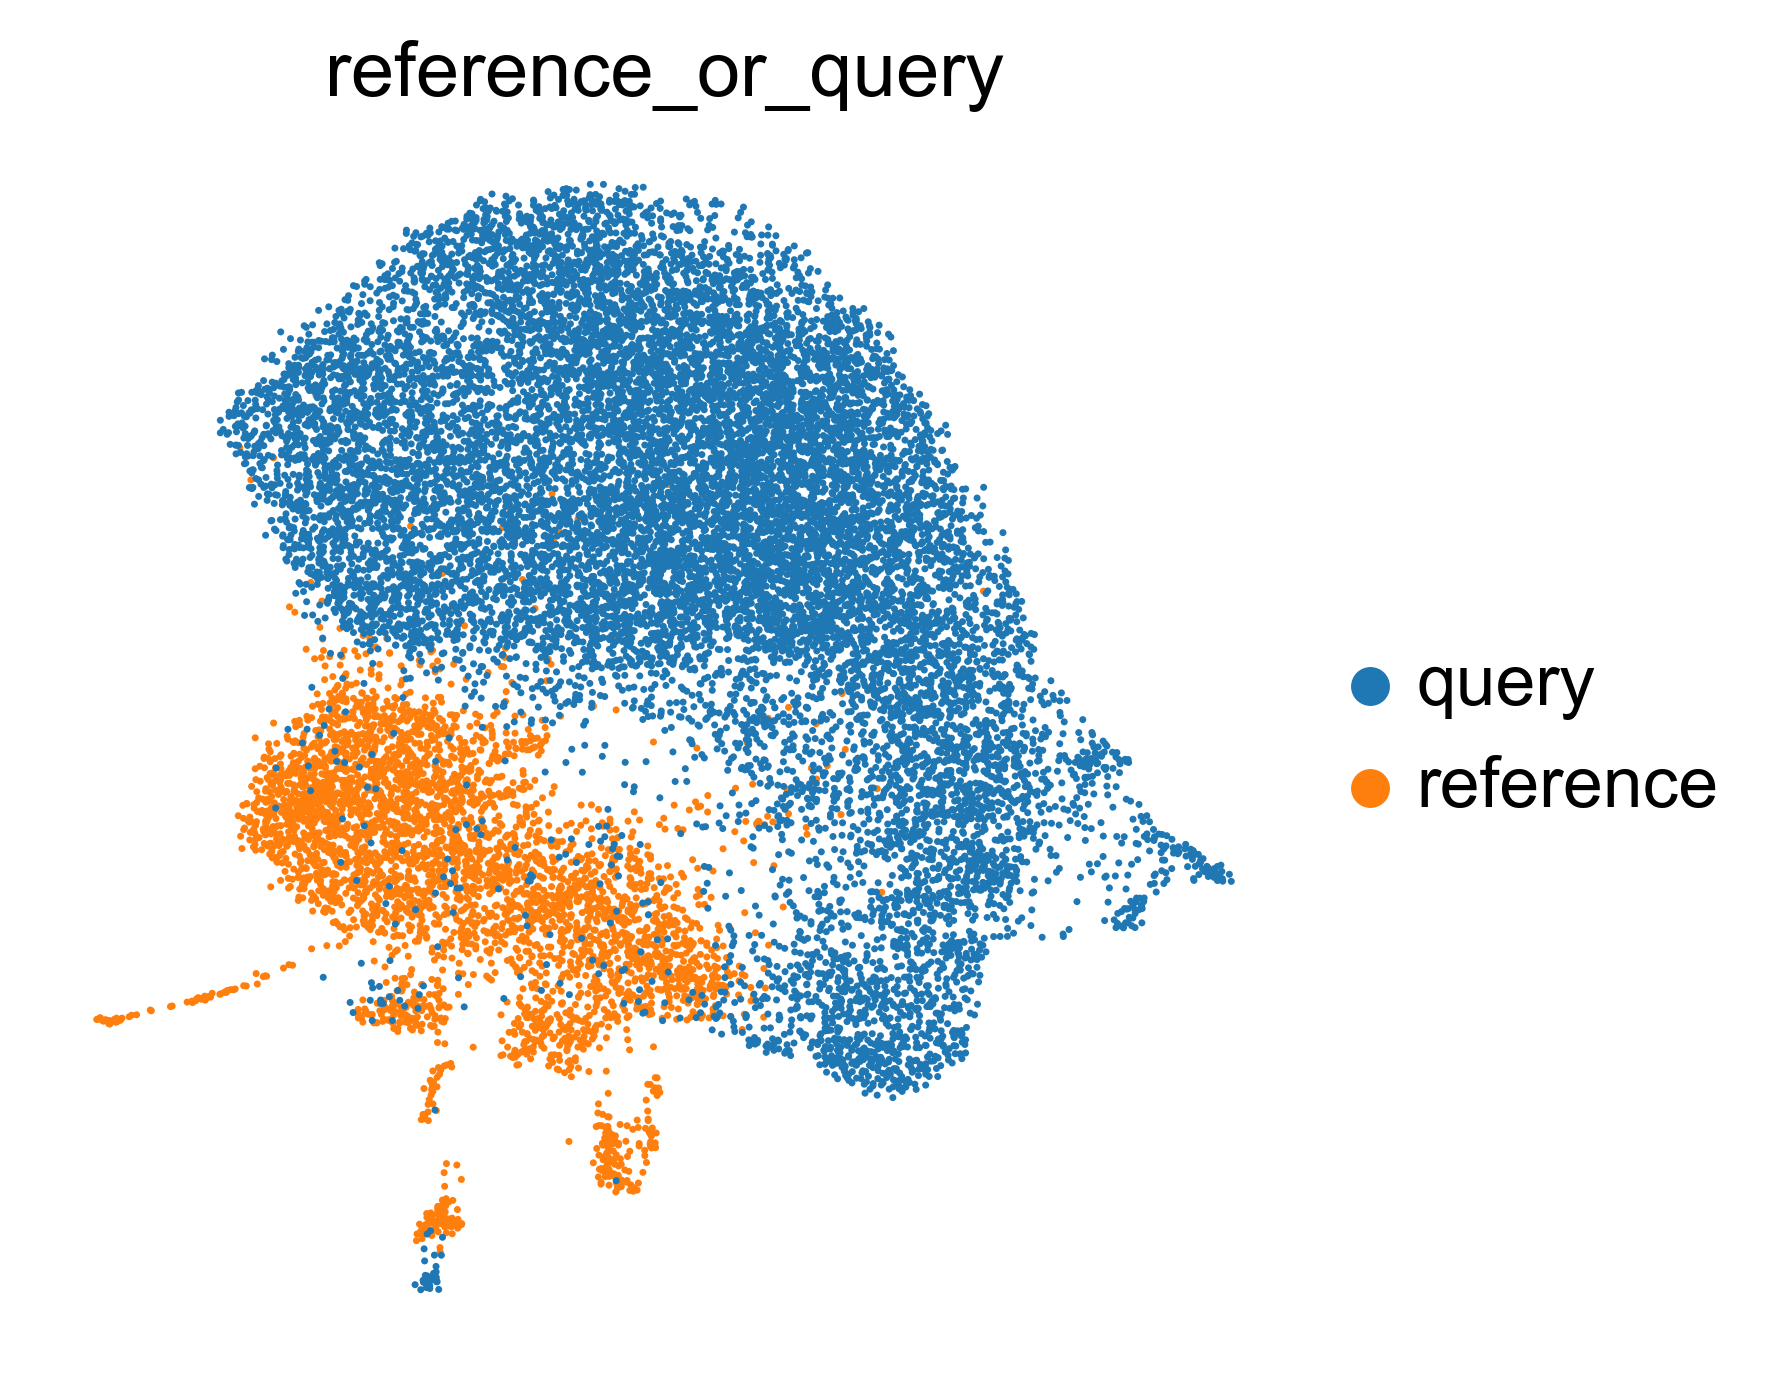

In [345]:
sc.pl.umap(
    emb_ref_query,
    color=["reference_or_query"],
    sort_order=False,
    frameon=False,
)

In [233]:
scarches_model = sca.models.SCVI.load_query_data(
    adata=adata_to_map_augmented,
    reference_model=str(model_dir),
    freeze_dropout=True,
)

INFO     File 2025-11-08-scvi-mus_musculus/scvi.model/model.pt already downloaded                                  


In [235]:
scarches_model.train(max_epochs=500, plan_kwargs={"weight_decay": 0.0})

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Training:   0%|          | 0/500 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=500` reached.


In [234]:
scvi.model.SCVI.prepare_query_anndata(adata_herault, vae_ref)

INFO     Found 100.0% reference vars in query data.                                                                


In [112]:
vae_q = scvi.model.SCVI.load_query_data(adata_herault, vae_ref)

In [113]:
model_dir = Path("./hsc_FACS.pt/")
model_dir.mkdir(parents=True, exist_ok=True)

In [132]:
vae_q.train(max_epochs=20)  # fast re-training for input weights

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Training:   0%|          | 0/20 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=20` reached.


In [133]:
# getting embedding represantation of our query
adata_herault.obsm["X_scvi"] = vae_q.get_latent_representation()

In [134]:
scarches_model.train(max_epochs=500, plan_kwargs={"weight_decay": 0.0})

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Training:   0%|          | 0/500 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=500` reached.


In [136]:
adata_to_map.obsm["X_scVI"] = scarches_model.get_latent_representation()

In [137]:
sc.pp.neighbors(adata_to_map, use_rep="X_scVI")

In [138]:
sc.tl.umap(adata_to_map)

In [ ]:
sc.pl.umap(
    adata,
    color=["IGHD", "IGHM", "PRDM1"],
    vmin=0,
    vmax="p99",  # set vmax to the 99th percentile of the gene count instead of the maximum, to prevent outliers from making expression in other cells invisible. Note that this can cause problems for extremely lowly expressed genes.
    sort_order=False,  # do not plot highest expression on top, to not get a biased view of the mean expression among cells
    frameon=False,
    cmap="Reds",  # or choose another color map e.g. from here: https://matplotlib.org/stable/tutorials/colors/colormaps.html
)

In [ ]:
ref_emb.obs["reference_or_query"] = "reference"

In [ ]:
ref_emb

In [ ]:
adata_emb = sc.AnnData(X=adata_to_map.obsm["X_scVI"], obs=adata.obs)

In [ ]:
adata_emb.obs["reference_or_query"] = "query"

In [ ]:
adata_emb.obs["cell_type"] = None

In [ ]:
emb_ref_query = sc.concat(
    [ref_emb, adata_emb],
    axis=0,
    join="outer",
    index_unique=None,
    merge="unique",
)

In [ ]:
sc.pp.neighbors(emb_ref_query)
sc.tl.umap(emb_ref_query)

In [ ]:
sc.pl.umap(
    emb_ref_query,
    color=["reference_or_query"],
    sort_order=False,
    frameon=False,
)

## Exporting metadata (**annotated cell types**)

Here we export the obtained data, to use it for integration/trajectory inference.

In [ ]:
metadata.to_csv("cell_annotation_metadata.tsv", sep="\t")

In [ ]:
metadata